# Analisis Sentimen Program Makan Bergizi Gratis (MBG)

**Dataset:** `makangratis_valid.csv`  
**Lokasi Google Drive:** `/content/drive/MyDrive/analisis_sentimen_mbg_effie/`

Notebook ini dirancang untuk penelitian skripsi dengan pipeline utama:

**Tweet → cleaning media sosial → normalisasi Bahasa Indonesia → preservasi negasi → selective stopword removal → pretrained FastText Indonesia 300D → SIF sentence embedding → classical machine learning**

Kandidat classifier:
- Logistic Regression
- Linear SVM
- RBF-SVM
- Random Forest
- XGBoost

Strategi ketidakseimbangan kelas:
- cost-sensitive / class weighting
- SMOTE

Evaluasi:
- Accuracy
- Precision
- Recall
- F1-score
- Macro-F1
- Weighted-F1
- Balanced Accuracy
- Confusion Matrix

## Prinsip reproducibility

1. Dataset diberi **SHA-256 hash**.
2. Split train/test dibuat satu kali dan disimpan permanen.
3. Stratified 5-Fold CV dibuat satu kali dan disimpan.
4. Setiap artefak memiliki hash konfigurasi.
5. Jika dataset/lexicon/config berubah, artefak downstream otomatis memakai hash baru.
6. Hasil CV disimpan **per fold dan per konfigurasi**, sehingga eksperimen dapat dilanjutkan setelah runtime terputus.
7. Final test set tidak dipakai untuk memilih hyperparameter/model.

> **Catatan:** Paper terdahulu dipakai sebagai *analytical comparison* dalam naskah skripsi, bukan sebagai baseline yang direplikasi oleh notebook ini.

## 00 — Instalasi dependensi

Jalankan cell ini setiap membuka runtime Colab baru. Instalasi package bukan artefak penelitian; versi aktual package akan direkam ke `environment.json`.

Pretrained FastText menggunakan word vectors Bahasa Indonesia resmi dari fastText:
`cc.id.300.vec.gz` (Common Crawl + Wikipedia, dimensi 300).

In [ ]:
!pip -q install emoji Sastrawi imbalanced-learn xgboost

## 01 — Mount Google Drive dan konfigurasi global

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, re, json, hashlib, html, unicodedata, gzip, shutil, subprocess, sys
from collections import Counter
from datetime import datetime
import importlib.metadata as md_pkg

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterGrid
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, f1_score,
    balanced_accuracy_score, confusion_matrix, classification_report
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
import emoji

# ============================================================
# LOKASI UTAMA
# ============================================================
ROOT = Path('/content/drive/MyDrive/analisis_sentimen_mbg_effie')
DATASET_PATH = ROOT / 'makangratis_valid.csv'
ART = ROOT / 'artifacts'

DIRS = {
    'dataset': ART / '00_dataset',
    'normalization': ART / '01_normalization',
    'preprocessing': ART / '02_preprocessing',
    'fasttext': ART / '03_fasttext',
    'embeddings': ART / '04_embeddings',
    'splits': ART / '05_splits',
    'models': ART / '06_models',
    'results': ART / '07_results',
    'figures': ART / '08_figures',
    'manifests': ART / '09_manifests',
}
ROOT.mkdir(parents=True, exist_ok=True)
for p in DIRS.values():
    p.mkdir(parents=True, exist_ok=True)

# ============================================================
# KONFIGURASI PENELITIAN
# ============================================================
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
SIF_A = 1e-3

TEXT_COL = 'full_text'
LABEL_COL = 'label'
LABEL_MAP = {'N': 0, 'P': 1}
LABEL_NAME = {0: 'Negatif', 1: 'Positif'}

# Increment jika logika inti eksperimen sengaja diubah.
EXPERIMENT_VERSION = 'MBG_FT_SIF_V1'

# Stopword dilakukan selektif.
USE_SELECTIVE_STOPWORDS = True

# Kata-kata ini TIDAK BOLEH dibuang walaupun muncul pada daftar stopword.
PRESERVE_WORDS = {
    'tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang',
    'tapi', 'tetapi', 'namun', 'masih',
    'sangat', 'amat', 'lebih', 'paling', 'terlalu',
    'bisa', 'mau', 'harus'
}

# Sumber pretrained FastText resmi.
FASTTEXT_VEC_URL = (
    'https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/'
    'cc.id.300.vec.gz'
)
FASTTEXT_DIM = 300

# File .vec.gz hanya dibutuhkan pada run pertama.
# Setelah vector cache untuk vocabulary dataset berhasil dibuat,
# file besar lokal /content akan dihapus.
DELETE_FASTTEXT_DOWNLOAD_AFTER_CACHE = True

print('ROOT           :', ROOT)
print('DATASET        :', DATASET_PATH)
print('EXPERIMENT     :', EXPERIMENT_VERSION)
print('RANDOM_STATE   :', RANDOM_STATE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROOT           : /content/drive/MyDrive/analisis_sentimen_mbg_effie
DATASET        : /content/drive/MyDrive/analisis_sentimen_mbg_effie/makangratis_valid.csv
EXPERIMENT     : MBG_FT_SIF_V1
RANDOM_STATE   : 42


## 02 — Helper reproducibility, hashing, dan metadata

In [ ]:
def sha256_file(path, chunk_size=1024 * 1024):
    path = Path(path)
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

def stable_hash(obj):
    payload = json.dumps(
        obj, sort_keys=True, ensure_ascii=False, default=str
    ).encode('utf-8')
    return hashlib.sha256(payload).hexdigest()

def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2, default=str)

def load_json(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def now_iso():
    return datetime.now().astimezone().isoformat()

def package_version(name):
    try:
        return md_pkg.version(name)
    except Exception:
        return None

ENVIRONMENT = {
    'created_at': now_iso(),
    'python': sys.version,
    'packages': {
        'numpy': package_version('numpy'),
        'pandas': package_version('pandas'),
        'scikit-learn': package_version('scikit-learn'),
        'imbalanced-learn': package_version('imbalanced-learn'),
        'xgboost': package_version('xgboost'),
        'emoji': package_version('emoji'),
        'Sastrawi': package_version('Sastrawi'),
    }
}
save_json(ENVIRONMENT, DIRS['manifests'] / 'environment.json')
ENVIRONMENT

{'created_at': '2026-08-10T06:51:46.600853+00:00',
 'python': '3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]',
 'packages': {'numpy': '2.0.2',
  'pandas': '2.2.2',
  'scikit-learn': '1.6.1',
  'imbalanced-learn': '0.14.2',
  'xgboost': '3.3.0',
  'emoji': '2.15.0',
  'Sastrawi': '1.0.1'}}

## 03 — Load dan validasi dataset

Cell ini memastikan dataset benar-benar memiliki kolom `full_text` dan `label`, label hanya `N/P`, serta membuat `row_id` permanen.

In [ ]:
assert DATASET_PATH.exists(), f'Dataset tidak ditemukan: {DATASET_PATH}'

DATASET_SHA = sha256_file(DATASET_PATH)
df = pd.read_csv(DATASET_PATH)

required_cols = {TEXT_COL, LABEL_COL}
missing_cols = required_cols - set(df.columns)
assert not missing_cols, f'Kolom wajib tidak ada: {missing_cols}'

df = df[[TEXT_COL, LABEL_COL]].copy()
df[TEXT_COL] = df[TEXT_COL].fillna('').astype(str)
df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip().str.upper()

unknown_labels = set(df[LABEL_COL].unique()) - set(LABEL_MAP)
assert not unknown_labels, f'Label tidak dikenal: {unknown_labels}'

df.insert(0, 'row_id', np.arange(len(df), dtype=int))
df['y'] = df[LABEL_COL].map(LABEL_MAP).astype(int)

print('Shape       :', df.shape)
print('SHA-256     :', DATASET_SHA)
print('\nDistribusi label:')
print(df[LABEL_COL].value_counts())

display(df.head())

Shape       : (656, 4)
SHA-256     : d66ae312972b3026d6ced349daaa4e6a48c3bb98965f10c7532ff5b74b367e51

Distribusi label:
label
N    533
P    123
Name: count, dtype: int64


,row_id,full_text,label,y
0,0,@iweng01 @akunbarublek @ignasbowo Tpi tujuan a...,N,0
1,1,BI Dukung Program Makan Siang Gratis Asalkan T...,P,1
2,2,@RizkiDimasDwij @masgah_ @Ipaahu La iya dana b...,N,0
3,3,@OposisiCerdas Ya di gaji sama makan siang gra...,N,0
4,4,"@RhendyW @marufins Sama kek stunting, solusiny...",N,0


## 04 — Profil dataset dan artefak statistik awal

In [ ]:
profile = {
    'dataset_file': DATASET_PATH.name,
    'dataset_sha256': DATASET_SHA,
    'n_rows': int(len(df)),
    'n_columns_original': 2,
    'text_column': TEXT_COL,
    'label_column': LABEL_COL,
    'label_distribution': {
        str(k): int(v) for k, v in df[LABEL_COL].value_counts().to_dict().items()
    },
    'duplicate_exact_text': int(df[TEXT_COL].duplicated().sum()),
    'empty_text': int(df[TEXT_COL].str.strip().eq('').sum()),
    'text_length_chars': {
        'min': int(df[TEXT_COL].str.len().min()),
        'median': float(df[TEXT_COL].str.len().median()),
        'mean': float(df[TEXT_COL].str.len().mean()),
        'max': int(df[TEXT_COL].str.len().max()),
    },
    'created_at': now_iso(),
}

save_json(profile, DIRS['dataset'] / 'dataset_profile.json')

label_dist = (
    df[LABEL_COL].value_counts()
    .rename_axis('label')
    .reset_index(name='jumlah')
)
label_dist['persentase'] = label_dist['jumlah'] / len(df) * 100
label_dist.to_csv(DIRS['dataset'] / 'label_distribution.csv', index=False)

dataset_hash_meta = {
    'dataset_sha256': DATASET_SHA,
    'experiment_version': EXPERIMENT_VERSION
}
save_json(dataset_hash_meta, DIRS['dataset'] / 'dataset_hash.json')

display(label_dist)
profile

,label,jumlah,persentase
0,N,533,81.25
1,P,123,18.75


{'dataset_file': 'makangratis_valid.csv',
 'dataset_sha256': 'd66ae312972b3026d6ced349daaa4e6a48c3bb98965f10c7532ff5b74b367e51',
 'n_rows': 656,
 'n_columns_original': 2,
 'text_column': 'full_text',
 'label_column': 'label',
 'label_distribution': {'N': 533, 'P': 123},
 'duplicate_exact_text': 0,
 'empty_text': 0,
 'text_length_chars': {'min': 27,
  'median': 147.5,
  'mean': 165.42073170731706,
  'max': 345},
 'created_at': '2026-08-10T06:51:54.315057+00:00'}

## 05 — Kamus normalisasi Bahasa Indonesia

Notebook memakai dua lapis lexicon:

1. **Lexicon umum**: *Colloquial Indonesian Lexicon*.
2. **Lexicon khusus dataset MBG**: file yang dapat diedit manual di Drive.

`lexicon_mbg.csv` hanya dibuat otomatis jika belum ada. Setelah itu notebook **tidak akan menimpa edit manual Anda**.

Urutan prioritas:
**lexicon umum → ditimpa lexicon MBG**.

In [ ]:
import urllib.request

GENERAL_LEXICON_RAW_URL = (
    'https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/'
    'colloquial-indonesian-lexicon.csv'
)

general_path = DIRS['normalization'] / 'lexicon_general.csv'
domain_path = DIRS['normalization'] / 'lexicon_mbg.csv'
final_path = DIRS['normalization'] / 'lexicon_final.csv'

# -----------------------------
# 1. Lexicon umum
# -----------------------------
if not general_path.exists():
    print('Mengunduh lexicon umum...')
    tmp = DIRS['normalization'] / '_colloquial_indonesian_lexicon_raw.csv'
    urllib.request.urlretrieve(GENERAL_LEXICON_RAW_URL, tmp)
    raw_lex = pd.read_csv(tmp)

    assert {'slang', 'formal'}.issubset(raw_lex.columns), \
        'Format lexicon umum berubah.'

    general_lex = raw_lex[['slang', 'formal']].dropna().copy()
    general_lex['slang'] = (
        general_lex['slang'].astype(str).str.strip().str.lower()
    )
    general_lex['formal'] = (
        general_lex['formal'].astype(str).str.strip().str.lower()
    )
    general_lex = (
        general_lex[
            general_lex['slang'].ne('') &
            general_lex['formal'].ne('')
        ]
        .drop_duplicates('slang', keep='first')
        .sort_values('slang')
        .reset_index(drop=True)
    )
    general_lex.to_csv(general_path, index=False)
    tmp.unlink(missing_ok=True)
else:
    general_lex = pd.read_csv(general_path)

print('Lexicon umum:', len(general_lex), 'entri')

# -----------------------------
# 2. Lexicon khusus MBG
#    Dibuat sekali, lalu bebas diedit.
# -----------------------------
DEFAULT_MBG_LEXICON = {
    'yg': 'yang',
    'gak': 'tidak',
    'ga': 'tidak',
    'gk': 'tidak',
    'nggak': 'tidak',
    'ngga': 'tidak',
    'nggk': 'tidak',
    'tdk': 'tidak',
    'gatau': 'tidak tahu',
    'udah': 'sudah',
    'udh': 'sudah',
    'kalo': 'kalau',
    'klo': 'kalau',
    'kl': 'kalau',
    'krn': 'karena',
    'karna': 'karena',
    'dgn': 'dengan',
    'tp': 'tapi',
    'tpi': 'tapi',
    'jd': 'jadi',
    'dapet': 'dapat',
    'gimana': 'bagaimana',
    'gmn': 'bagaimana',
    'bgt': 'sangat',
    'sgt': 'sangat',
    'aja': 'saja',
    'sm': 'sama',
    'dr': 'dari',
    'utk': 'untuk',
    'skrg': 'sekarang',
    'skrng': 'sekarang',
    'pnya': 'punya',
    'kbnykn': 'kebanyakan',
    'dimkn': 'dimakan',
    'jls': 'jelas',
    'msh': 'masih',
    'blm': 'belum',
    'emg': 'memang',
    'emang': 'memang',
    'kayak': 'seperti',
    'kek': 'seperti',
    'trs': 'terus',
    'trus': 'terus',
    'bener': 'benar',
    'beneran': 'benar',
    'gue': 'saya',
    'gw': 'saya',
    'lu': 'kamu',
    'lo': 'kamu',
    'org': 'orang',
    'gt': 'begitu',
    'gtu': 'begitu',
    'gitu': 'begitu',
}

if not domain_path.exists():
    domain_lex = pd.DataFrame(
        [{'slang': k, 'formal': v} for k, v in DEFAULT_MBG_LEXICON.items()]
    ).sort_values('slang')
    domain_lex.to_csv(domain_path, index=False)
    print('Dibuat:', domain_path)
    print('Silakan edit file ini di Drive jika diperlukan, lalu jalankan ulang mulai cell ini.')
else:
    domain_lex = pd.read_csv(domain_path)

for col in ['slang', 'formal']:
    domain_lex[col] = domain_lex[col].astype(str).str.strip().str.lower()
domain_lex = (
    domain_lex.dropna()
    .drop_duplicates('slang', keep='last')
    .reset_index(drop=True)
)

# -----------------------------
# 3. Merge. Domain lexicon override general.
# -----------------------------
general_map = dict(zip(general_lex['slang'], general_lex['formal']))
domain_map = dict(zip(domain_lex['slang'], domain_lex['formal']))
final_map = {**general_map, **domain_map}

final_lex = pd.DataFrame(
    [{'slang': k, 'formal': v} for k, v in final_map.items()]
).sort_values('slang').reset_index(drop=True)
final_lex.to_csv(final_path, index=False)

LEXICON_SHA = sha256_file(final_path)

print('Lexicon MBG  :', len(domain_lex))
print('Lexicon final:', len(final_lex))
print('Lexicon SHA  :', LEXICON_SHA)

display(domain_lex.head(20))

Lexicon umum: 4330 entri
Lexicon MBG  : 53
Lexicon final: 4338
Lexicon SHA  : 4a39bc5bbb99843d9f33c40ea39aa388aa851e9e5987a823b2ac63a4bf16c06b


,slang,formal
0,aja,saja
1,bener,benar
2,beneran,benar
3,bgt,sangat
4,blm,belum
5,dapet,dapat
6,dgn,dengan
7,dimkn,dimakan
8,dr,dari
9,emang,memang


## 06 — Konfigurasi preprocessing

Tahapan implementasi:

1. Unicode normalization.
2. Hashtag extraction/segmentation *(dilakukan sebelum lower-case agar CamelCase masih dapat dibaca)*.
3. Case folding.
4. URL cleaning.
5. Mention cleaning.
6. RT marker cleaning.
7. Emoji normalization.
8. Repeated-character normalization.
9. Punctuation / pure-number cleaning.
10. Tokenization.
11. Indonesian lexical normalization.
12. Negation preservation.
13. Selective stopword removal.
14. **Tanpa stemming** pada pipeline utama.

Emoji tidak langsung dibuang. Emoji umum dikonversi ke token semantik sederhana.

In [ ]:
PREPROCESS_CONFIG = {
    'experiment_version': EXPERIMENT_VERSION,
    'unicode_form': 'NFKC',
    'case_folding': True,
    'remove_url': True,
    'remove_mentions': True,
    'remove_rt_marker': True,
    'normalize_hashtags': True,
    'normalize_emoji': True,
    'normalize_repeated_chars_3plus': True,
    'remove_punctuation': True,
    'remove_pure_numbers': True,
    'lexical_normalization': True,
    'lexicon_sha256': LEXICON_SHA,
    'selective_stopwords': USE_SELECTIVE_STOPWORDS,
    'preserve_words': sorted(PRESERVE_WORDS),
    'stemming': False,
}
PREPROCESS_HASH = stable_hash({
    'dataset_sha256': DATASET_SHA,
    'preprocess_config': PREPROCESS_CONFIG
})

print('PREPROCESS_HASH:', PREPROCESS_HASH)
save_json(PREPROCESS_CONFIG, DIRS['preprocessing'] / f'preprocess_config_{PREPROCESS_HASH[:12]}.json')

PREPROCESS_HASH: 6ce71e6aa9d60e1fe37266000ed664c30c2ed74113190b90e567ec839979ff37


## 07 — Fungsi preprocessing

In [ ]:
# Emoji yang paling umum untuk ekspresi sentimen.
EMOJI_POS = set('😀😃😄😁😊😍🥰😘🙂😇🤩❤❤️💚💙💜🤍👍👏🙏✨🥳')
EMOJI_NEG = set('😞😔😟🙁☹😢😭😥😓😩😫😡😠🤬😤👎💔😒🙄')
EMOJI_LAUGH = set('😂🤣😹')
EMOJI_SURPRISE = set('😮😯😲🤯')

def split_camel_hashtag(tag):
    # Contoh: MakanBergiziGratis -> Makan Bergizi Gratis
    tag = tag.replace('_', ' ')
    tag = re.sub(r'(?<=[a-z])(?=[A-Z])', ' ', tag)
    return tag

def replace_hashtag(match):
    return ' ' + split_camel_hashtag(match.group(1)) + ' '

def emoji_token(ch):
    if ch in EMOJI_POS:
        return ' emoji_positif '
    if ch in EMOJI_NEG:
        return ' emoji_negatif '
    if ch in EMOJI_LAUGH:
        return ' emoji_tawa '
    if ch in EMOJI_SURPRISE:
        return ' emoji_terkejut '
    return ' emoji '

def normalize_emojis(text):
    items = emoji.emoji_list(text)
    # Replace sequence dari kanan ke kiri agar indeks tidak bergeser.
    for item in reversed(items):
        start, end = item['match_start'], item['match_end']
        ch = item['emoji']
        text = text[:start] + emoji_token(ch) + text[end:]
    return text

def basic_clean(text):
    text = html.unescape(str(text))
    text = unicodedata.normalize('NFKC', text)

    # Hashtag sebelum case-fold supaya CamelCase dapat dipisahkan.
    text = re.sub(r'#([A-Za-z0-9_]+)', replace_hashtag, text)

    text = text.lower()

    # URL
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Mention
    text = re.sub(r'@\w+', ' ', text)

    # RT marker
    text = re.sub(r'(^|\s)rt(?=\s|$)', ' ', text)

    # Emoji -> token
    text = normalize_emojis(text)

    # Normalisasi karakter berulang >= 3.
    # "baguuuus" -> "bagus"; double-letter legal tidak disentuh.
    text = re.sub(r'(.)\1{2,}', r'\1', text)

    # Buang angka murni dan punctuation.
    text = re.sub(r'\b\d+\b', ' ', text)
    # Pertahankan underscore agar token emoji_positif tidak pecah.
    text = re.sub(r'[^a-z_\s]', ' ', text)

    # Whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

STOPWORDS = set(StopWordRemoverFactory().get_stop_words())
STOPWORDS_SELECTIVE = STOPWORDS - PRESERVE_WORDS

replacement_counter = Counter()

def lexical_normalize_tokens(tokens, lexicon, count_replacements=False):
    result = []
    for tok in tokens:
        replacement = lexicon.get(tok, tok)
        if replacement != tok and count_replacements:
            replacement_counter[(tok, replacement)] += 1

        # Formal replacement dapat berisi lebih dari satu kata.
        repl_tokens = re.findall(r'[a-z_]+', replacement.lower())
        result.extend(repl_tokens if repl_tokens else [tok])
    return result

def preprocess_one(text, lexicon, count_replacements=False):
    cleaned = basic_clean(text)
    tokens_raw = re.findall(r'[a-z_]+', cleaned)

    tokens_norm = lexical_normalize_tokens(
        tokens_raw, lexicon,
        count_replacements=count_replacements
    )

    # Selective stopword removal.
    if USE_SELECTIVE_STOPWORDS:
        tokens_final = [
            t for t in tokens_norm
            if (t not in STOPWORDS_SELECTIVE) or (t in PRESERVE_WORDS)
        ]
    else:
        tokens_final = tokens_norm

    normalized_text = ' '.join(tokens_norm)
    preprocessed_text = ' '.join(tokens_final)

    return cleaned, normalized_text, preprocessed_text, tokens_final

# Contoh
sample = df.iloc[0][TEXT_COL]
print('RAW:\n', sample)
print('\nHASIL:\n', preprocess_one(sample, final_map)[2])

RAW:
 @iweng01 @akunbarublek @ignasbowo Tpi tujuan awal dari makan siang gratis ini kan untuk perbaikan gizi dan pencegahan stunting? Pencegahan stunting ini jls g efektif krn prio nya di anak sekolah, lalu gmn kl misal anak itu ga suka lauknya/pnya alergi? Anak kecil kbnykn picky eater jd berkemungkinan besar g dimkn

HASIL:
 tapi tujuan awal makan siang gratis kan perbaikan gizi pencegahan stunting pencegahan stunting jelas enggak efektif prio nya anak sekolah lalu bagaimana kalau misal anak tidak suka lauknya punya alergi anak kecil kebanyakan picky eater jadi berkemungkinan besar enggak dimakan


## 08 — Jalankan / load preprocessing

Artefak utama:
- `dataset_preprocessed_<hash>.csv`
- `normalization_report_<hash>.csv`
- `preprocessing_statistics_<hash>.json`

`tokens_json` disimpan agar tahapan embedding tidak perlu mengulang preprocessing.

In [ ]:
preprocessed_path = (
    DIRS['preprocessing'] /
    f'dataset_preprocessed_{PREPROCESS_HASH[:12]}.csv'
)
norm_report_path = (
    DIRS['normalization'] /
    f'normalization_report_{PREPROCESS_HASH[:12]}.csv'
)
prep_stats_path = (
    DIRS['preprocessing'] /
    f'preprocessing_statistics_{PREPROCESS_HASH[:12]}.json'
)

if preprocessed_path.exists():
    print('LOAD artefak preprocessing:', preprocessed_path)
    dfp = pd.read_csv(preprocessed_path)
    dfp['tokens'] = dfp['tokens_json'].apply(json.loads)
else:
    print('BUILD preprocessing...')
    replacement_counter.clear()

    records = []
    for row in df.itertuples(index=False):
        raw = getattr(row, TEXT_COL)
        cleaned, normalized, preprocessed, tokens = preprocess_one(
            raw, final_map, count_replacements=True
        )
        records.append({
            'row_id': int(row.row_id),
            'full_text': raw,
            'label': getattr(row, LABEL_COL),
            'y': int(row.y),
            'clean_text': cleaned,
            'normalized_text': normalized,
            'preprocessed_text': preprocessed,
            'tokens_json': json.dumps(tokens, ensure_ascii=False),
        })

    dfp = pd.DataFrame(records)
    dfp['tokens'] = dfp['tokens_json'].apply(json.loads)
    dfp.drop(columns=['tokens']).to_csv(preprocessed_path, index=False)
    dfp['tokens'] = dfp['tokens_json'].apply(json.loads)

    # Laporan replacement
    norm_rows = [
        {
            'slang': slang,
            'formal': formal,
            'jumlah_penggantian': count
        }
        for (slang, formal), count in replacement_counter.items()
    ]
    norm_report = pd.DataFrame(norm_rows)
    if len(norm_report):
        norm_report = norm_report.sort_values(
            'jumlah_penggantian', ascending=False
        )
    norm_report.to_csv(norm_report_path, index=False)

    token_lengths = dfp['tokens'].apply(len)
    prep_stats = {
        'preprocess_hash': PREPROCESS_HASH,
        'dataset_sha256': DATASET_SHA,
        'n_rows': int(len(dfp)),
        'empty_after_preprocessing': int((token_lengths == 0).sum()),
        'tokens_per_tweet': {
            'min': int(token_lengths.min()),
            'median': float(token_lengths.median()),
            'mean': float(token_lengths.mean()),
            'max': int(token_lengths.max()),
        },
        'normalization_replacements_total': int(
            sum(replacement_counter.values())
        ),
        'unique_normalization_pairs_used': int(
            len(replacement_counter)
        ),
        'created_at': now_iso(),
    }
    save_json(prep_stats, prep_stats_path)

print('Preprocessed:', dfp.shape)
display(dfp[['row_id', 'full_text', 'normalized_text', 'preprocessed_text', 'label']].head(10))

if norm_report_path.exists():
    nr = pd.read_csv(norm_report_path)
    print('\nNormalisasi paling sering:')
    display(nr.head(30))

LOAD artefak preprocessing: /content/drive/MyDrive/analisis_sentimen_mbg_effie/artifacts/02_preprocessing/dataset_preprocessed_6ce71e6aa9d6.csv
Preprocessed: (656, 9)


,row_id,full_text,normalized_text,preprocessed_text,label
0,0,@iweng01 @akunbarublek @ignasbowo Tpi tujuan a...,tapi tujuan awal dari makan siang gratis ini k...,tapi tujuan awal makan siang gratis kan perbai...,N
1,1,BI Dukung Program Makan Siang Gratis Asalkan T...,bi dukung program makan siang gratis asalkan t...,bi dukung program makan siang gratis asalkan t...,P
2,2,@RizkiDimasDwij @masgah_ @Ipaahu La iya dana b...,lah iya dana bos saja dikorup apalagi ada proy...,lah iya dana bos dikorup proyek makan siang gr...,N
3,3,@OposisiCerdas Ya di gaji sama makan siang gra...,ya di gaji sama makan siang gratis lah,gaji sama makan siang gratis lah,N
4,4,"@RhendyW @marufins Sama kek stunting, solusiny...",sama seperti stunting solusinya makan siang gr...,sama stunting solusinya makan siang gratis men...,N
5,5,@MrsTitins @ZackXChristy @akunbarublek @ignasb...,tidak baca programnya apa bagaimana ya targetn...,tidak baca programnya apa bagaimana targetnya ...,P
6,6,PKS: Kalau Dana BOS Dipakai Makan Siang Gratis...,pks kalau dana bos dipakai makan siang gratis ...,pks kalau dana bos dipakai makan siang gratis ...,N
7,7,https://t.co/LhpkGDxLR6 Bank Indonesia dukung ...,bank indonesia dukung program makan siang gratis,bank indonesia dukung program makan siang gratis,P
8,8,@KangManto123 makan siang gratis receh sampe h...,makan siang gratis receh sampai harus pakai da...,makan siang gratis receh harus pakai dana bos _,N
9,9,@YandraD31 Buat Gemoy Lover ndak sampai mikir ...,buat gemoy lover indak sampai mikir ke situ ba...,buat gemoy lover indak mikir situ bang asal im...,N



Normalisasi paling sering:


,slang,formal,jumlah_penggantian
0,yg,yang,263
1,aja,saja,120
2,gak,tidak,79
3,ga,tidak,78
4,udah,sudah,49
5,lu,kamu,46
6,kalo,kalau,34
7,milih,memilih,34
8,emang,memang,30
9,krn,karena,25


## 09 — Kunci train/test split dan Stratified 5-Fold CV

**Split dibuat berdasarkan `row_id` dan disimpan sebagai artefak.**

- 80% development/train
- 20% final unseen test
- stratified menurut label
- `random_state = 42`

**Final test tidak digunakan pada pencarian hyperparameter.**

In [ ]:
split_config = {
    'dataset_sha256': DATASET_SHA,
    'test_size': TEST_SIZE,
    'random_state': RANDOM_STATE,
    'n_splits_cv': N_SPLITS,
    'stratified': True,
    'experiment_version': EXPERIMENT_VERSION,
}
SPLIT_HASH = stable_hash(split_config)

split_npz = DIRS['splits'] / f'train_test_{SPLIT_HASH[:12]}.npz'
folds_json = DIRS['splits'] / f'cv_folds_{SPLIT_HASH[:12]}.json'
split_meta = DIRS['splits'] / f'split_metadata_{SPLIT_HASH[:12]}.json'

all_row_ids = dfp['row_id'].to_numpy()
all_y = dfp['y'].to_numpy()

if split_npz.exists() and folds_json.exists():
    print('LOAD split permanen')
    z = np.load(split_npz)
    train_ids = z['train_row_ids'].astype(int)
    test_ids = z['test_row_ids'].astype(int)
    folds = load_json(folds_json)['folds']
else:
    print('BUILD split permanen')
    train_ids, test_ids = train_test_split(
        all_row_ids,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=all_y
    )
    train_ids = np.sort(train_ids.astype(int))
    test_ids = np.sort(test_ids.astype(int))

    np.savez_compressed(
        split_npz,
        train_row_ids=train_ids,
        test_row_ids=test_ids
    )

    train_df_tmp = dfp.set_index('row_id').loc[train_ids].reset_index()
    skf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    folds = []
    for fold_no, (tr_pos, va_pos) in enumerate(
        skf.split(train_df_tmp['row_id'], train_df_tmp['y']), start=1
    ):
        folds.append({
            'fold': fold_no,
            'train_row_ids': train_df_tmp.iloc[tr_pos]['row_id'].astype(int).tolist(),
            'val_row_ids': train_df_tmp.iloc[va_pos]['row_id'].astype(int).tolist(),
        })

    save_json({'folds': folds}, folds_json)
    save_json({
        **split_config,
        'split_hash': SPLIT_HASH,
        'n_train': int(len(train_ids)),
        'n_test': int(len(test_ids)),
        'created_at': now_iso(),
    }, split_meta)

def show_dist(ids, name):
    d = dfp[dfp['row_id'].isin(ids)]
    print(name, len(d), d['label'].value_counts().to_dict())

show_dist(train_ids, 'TRAIN/DEV')
show_dist(test_ids, 'FINAL TEST')
print('SPLIT_HASH:', SPLIT_HASH)

LOAD split permanen
TRAIN/DEV 524 {'N': 426, 'P': 98}
FINAL TEST 132 {'N': 107, 'P': 25}
SPLIT_HASH: 0b9e96f22350b1cfaa3ffe5fee49c2be93f0c9dc7176f582d9e668ebea2faf09


## 10 — Bangun / load FastText token-vector cache

Untuk Colab, notebook **tidak menyimpan seluruh model FastText multi-GB ke RAM/Drive**.

Strateginya:

1. Ambil vocabulary unik yang benar-benar muncul setelah preprocessing.
2. Download resmi `cc.id.300.vec.gz` ke storage lokal Colab pada run pertama.
3. Stream file tersebut baris demi baris.
4. Simpan hanya vector 300D untuk token dataset.
5. Artefak kecil `fasttext_token_vectors_<hash>.npz` disimpan di Google Drive.
6. Run berikutnya langsung load artefak tersebut dan **tidak download FastText lagi** selama preprocessing/vocabulary tidak berubah.

Catatan metodologis: karena mode hemat-RAM ini memakai format **text vectors**, token OOV tidak mendapat vector subword secara on-the-fly seperti format binary. Karena itu notebook secara eksplisit menyimpan **coverage/OOV report**. Normalisasi Bahasa Indonesia dilakukan sebelum embedding untuk meningkatkan coverage.

In [ ]:
all_tokens = [t for toks in dfp['tokens'] for t in toks]
vocab = sorted(set(all_tokens))

VOCAB_HASH = stable_hash({
    'preprocess_hash': PREPROCESS_HASH,
    'vocab': vocab,
    'fasttext_source': FASTTEXT_VEC_URL,
    'dimension': FASTTEXT_DIM
})

ft_cache_path = DIRS['fasttext'] / f'fasttext_token_vectors_{VOCAB_HASH[:12]}.npz'
ft_meta_path = DIRS['fasttext'] / f'fasttext_metadata_{VOCAB_HASH[:12]}.json'
oov_path = DIRS['fasttext'] / f'oov_report_{VOCAB_HASH[:12]}.csv'

def save_vector_cache(vector_map, path):
    tokens = sorted(vector_map.keys())
    vectors = np.vstack([vector_map[t] for t in tokens]).astype(np.float32)
    np.savez_compressed(
        path,
        tokens=np.array(tokens, dtype=str),
        vectors=vectors
    )

def load_vector_cache(path):
    z = np.load(path, allow_pickle=False)
    tokens = z['tokens'].astype(str)
    vectors = z['vectors'].astype(np.float32)
    return {t: vectors[i] for i, t in enumerate(tokens)}

if ft_cache_path.exists():
    print('LOAD FastText vector cache:', ft_cache_path)
    ft_vectors = load_vector_cache(ft_cache_path)
else:
    print('BUILD FastText vector cache')
    print('Vocabulary unik:', len(vocab))

    local_gz = Path('/content/cc.id.300.vec.gz')
    if not local_gz.exists():
        print('Download FastText resmi. Ini hanya diperlukan pada run pertama...')
        subprocess.run([
            'wget', '-c', FASTTEXT_VEC_URL,
            '-O', str(local_gz)
        ], check=True)

    vocab_set = set(vocab)
    found = {}
    total_lines = 0

    print('Streaming pretrained vectors...')
    with gzip.open(local_gz, 'rt', encoding='utf-8', errors='ignore') as f:
        header = f.readline().strip()
        print('Header FastText:', header)

        for line_no, line in enumerate(f, start=1):
            total_lines += 1
            if line_no % 500_000 == 0:
                print(
                    f'  scanned={line_no:,} | '
                    f'found={len(found):,}/{len(vocab):,}'
                )

            try:
                word, vec_str = line.rstrip('\n').split(' ', 1)
            except ValueError:
                continue

            if word not in vocab_set:
                continue

            vec = np.fromstring(vec_str, sep=' ', dtype=np.float32)
            if vec.shape[0] == FASTTEXT_DIM:
                found[word] = vec

            if len(found) == len(vocab_set):
                print('Semua vocabulary ditemukan; streaming dihentikan.')
                break

    ft_vectors = found
    save_vector_cache(ft_vectors, ft_cache_path)

    if DELETE_FASTTEXT_DOWNLOAD_AFTER_CACHE:
        local_gz.unlink(missing_ok=True)
        print('File FastText besar lokal dihapus setelah cache berhasil.')

# -------------------------
# Coverage report
# -------------------------
token_counts = Counter(all_tokens)
oov_rows = [
    {'token': t, 'frekuensi': int(c)}
    for t, c in token_counts.items()
    if t not in ft_vectors
]
oov_df = pd.DataFrame(oov_rows)
if len(oov_df):
    oov_df = oov_df.sort_values('frekuensi', ascending=False)
oov_df.to_csv(oov_path, index=False)

covered_unique = len(ft_vectors)
total_unique = len(vocab)
total_occ = len(all_tokens)
covered_occ = sum(c for t, c in token_counts.items() if t in ft_vectors)

coverage_meta = {
    'vocab_hash': VOCAB_HASH,
    'preprocess_hash': PREPROCESS_HASH,
    'source': FASTTEXT_VEC_URL,
    'dimension': FASTTEXT_DIM,
    'unique_tokens_total': total_unique,
    'unique_tokens_covered': covered_unique,
    'unique_coverage_pct': (covered_unique / total_unique * 100) if total_unique else 0,
    'token_occurrences_total': total_occ,
    'token_occurrences_covered': int(covered_occ),
    'occurrence_coverage_pct': (covered_occ / total_occ * 100) if total_occ else 0,
    'created_at': now_iso(),
}
save_json(coverage_meta, ft_meta_path)

print(json.dumps(coverage_meta, indent=2))
print('\nOOV teratas:')
display(oov_df.head(50))

LOAD FastText vector cache: /content/drive/MyDrive/analisis_sentimen_mbg_effie/artifacts/03_fasttext/fasttext_token_vectors_686be1b9be17.npz
{
  "vocab_hash": "686be1b9be17498dc76271252b5605b5eebc5d4bc7b7abb3c774253e5609b37c",
  "preprocess_hash": "6ce71e6aa9d60e1fe37266000ed664c30c2ed74113190b90e567ec839979ff37",
  "source": "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.vec.gz",
  "dimension": 300,
  "unique_tokens_total": 2796,
  "unique_tokens_covered": 2636,
  "unique_coverage_pct": 94.27753934191702,
  "token_occurrences_total": 12212,
  "token_occurrences_covered": 11993,
  "occurrence_coverage_pct": 98.20668195217819,
  "created_at": "2026-08-10T06:52:29.088251+00:00"
}

OOV teratas:


,token,frekuensi
0,gemoy,19
20,kjmu,16
13,omon,4
30,wakanda,3
36,hakrakyat,3
95,jkw,3
35,janganmainin,3
16,dijogetin,2
18,covid,2
40,makansianggratis,2


## 11 — Fungsi FastText-SIF

SIF (*Smooth Inverse Frequency*) memberi bobot lebih besar pada kata informatif dan lebih kecil pada kata sangat umum.

Untuk mencegah leakage:
- probabilitas kata `p(w)` dihitung **hanya dari training fold**;
- principal component SIF juga di-fit **hanya dari training fold**;
- validation/test hanya ditransform dengan state dari training.

Ini dilakukan terpisah pada setiap fold CV.

In [ ]:
def fit_word_probs(token_lists):
    counts = Counter(t for toks in token_lists for t in toks)
    total = sum(counts.values())
    if total == 0:
        return {}
    return {w: c / total for w, c in counts.items()}

def raw_sif_embeddings(token_lists, vector_map, word_probs, a=SIF_A):
    X = np.zeros((len(token_lists), FASTTEXT_DIM), dtype=np.float32)

    for i, toks in enumerate(token_lists):
        vecs = []
        weights = []

        for w in toks:
            v = vector_map.get(w)
            if v is None:
                continue
            pw = word_probs.get(w, 0.0)
            weight = a / (a + pw)
            vecs.append(v)
            weights.append(weight)

        if vecs:
            V = np.vstack(vecs).astype(np.float32)
            W = np.asarray(weights, dtype=np.float32).reshape(-1, 1)
            X[i] = (V * W).sum(axis=0) / max(W.sum(), 1e-12)

    return X

def fit_sif(token_lists, vector_map, a=SIF_A):
    word_probs = fit_word_probs(token_lists)
    X_raw = raw_sif_embeddings(token_lists, vector_map, word_probs, a=a)

    nonzero = np.linalg.norm(X_raw, axis=1) > 0
    if nonzero.sum() >= 2:
        pca = PCA(n_components=1, random_state=RANDOM_STATE)
        pca.fit(X_raw[nonzero])
        pc = pca.components_[0].astype(np.float32)
    else:
        pc = np.zeros(FASTTEXT_DIM, dtype=np.float32)

    return {
        'word_probs': word_probs,
        'pc': pc,
        'a': a,
    }

def transform_sif(token_lists, vector_map, state):
    X_raw = raw_sif_embeddings(
        token_lists,
        vector_map,
        state['word_probs'],
        a=state['a']
    )
    pc = state['pc']
    if np.linalg.norm(pc) > 0:
        X = X_raw - np.outer(X_raw @ pc, pc)
    else:
        X = X_raw
    return X.astype(np.float32)

print('Fungsi SIF siap.')

Fungsi SIF siap.


## 12 — Cache FastText-SIF untuk 5 fold CV

Embeddings setiap fold dihitung satu kali lalu dipakai oleh seluruh classifier/hyperparameter.

In [ ]:
EMBED_HASH = stable_hash({
    'preprocess_hash': PREPROCESS_HASH,
    'vocab_hash': VOCAB_HASH,
    'split_hash': SPLIT_HASH,
    'embedding': 'FastText-SIF',
    'sif_a': SIF_A,
    'dimension': FASTTEXT_DIM,
    'anti_leakage': 'fit SIF probabilities and PC on fold-train only',
})

cv_embed_dir = DIRS['embeddings'] / f'cv_{EMBED_HASH[:12]}'
cv_embed_dir.mkdir(parents=True, exist_ok=True)

df_by_id = dfp.set_index('row_id')

for fold_info in folds:
    fold_no = int(fold_info['fold'])
    fold_path = cv_embed_dir / f'fold_{fold_no}.npz'

    if fold_path.exists():
        print(f'Fold {fold_no}: LOAD cache')
        continue

    print(f'Fold {fold_no}: BUILD FastText-SIF')
    tr_ids = np.array(fold_info['train_row_ids'], dtype=int)
    va_ids = np.array(fold_info['val_row_ids'], dtype=int)

    tr = df_by_id.loc[tr_ids]
    va = df_by_id.loc[va_ids]

    tr_tokens = tr['tokens'].tolist()
    va_tokens = va['tokens'].tolist()

    sif_state = fit_sif(tr_tokens, ft_vectors, a=SIF_A)
    X_tr = transform_sif(tr_tokens, ft_vectors, sif_state)
    X_va = transform_sif(va_tokens, ft_vectors, sif_state)

    np.savez_compressed(
        fold_path,
        X_train=X_tr,
        y_train=tr['y'].to_numpy(dtype=int),
        train_row_ids=tr_ids,
        X_val=X_va,
        y_val=va['y'].to_numpy(dtype=int),
        val_row_ids=va_ids,
    )

save_json({
    'embedding_hash': EMBED_HASH,
    'embedding': 'FastText-SIF',
    'sif_a': SIF_A,
    'dimension': FASTTEXT_DIM,
    'preprocess_hash': PREPROCESS_HASH,
    'vocab_hash': VOCAB_HASH,
    'split_hash': SPLIT_HASH,
    'created_at': now_iso(),
}, cv_embed_dir / 'metadata.json')

print('EMBED_HASH:', EMBED_HASH)

Fold 1: LOAD cache
Fold 2: LOAD cache
Fold 3: LOAD cache
Fold 4: LOAD cache
Fold 5: LOAD cache
EMBED_HASH: 38bc5e62e88b29b81ce92c0b31ae6bcfc4388aea58e04813727896b74ab7891e


## 13 — Cache FastText-SIF final train/test

State SIF final di-fit **hanya pada 80% train/dev**, kemudian digunakan untuk transform 20% final test.

In [ ]:
final_embed_dir = DIRS['embeddings'] / f'final_{EMBED_HASH[:12]}'
final_embed_dir.mkdir(parents=True, exist_ok=True)

final_embed_path = final_embed_dir / 'train_test_sif.npz'
final_sif_state_path = final_embed_dir / 'sif_state.joblib'

if final_embed_path.exists() and final_sif_state_path.exists():
    print('LOAD final embedding cache')
else:
    print('BUILD final train/test FastText-SIF')

    train_df = df_by_id.loc[train_ids]
    test_df = df_by_id.loc[test_ids]

    final_sif_state = fit_sif(
        train_df['tokens'].tolist(),
        ft_vectors,
        a=SIF_A
    )

    X_train_final = transform_sif(
        train_df['tokens'].tolist(), ft_vectors, final_sif_state
    )
    X_test_final = transform_sif(
        test_df['tokens'].tolist(), ft_vectors, final_sif_state
    )

    np.savez_compressed(
        final_embed_path,
        X_train=X_train_final,
        y_train=train_df['y'].to_numpy(dtype=int),
        train_row_ids=train_ids,
        X_test=X_test_final,
        y_test=test_df['y'].to_numpy(dtype=int),
        test_row_ids=test_ids,
    )
    joblib.dump(final_sif_state, final_sif_state_path)

zfinal = np.load(final_embed_path)
print('X_train:', zfinal['X_train'].shape)
print('X_test :', zfinal['X_test'].shape)

LOAD final embedding cache
X_train: (524, 300)
X_test : (132, 300)


## 14 — Ruang eksperimen classifier

Tidak ada TF-IDF/Naïve Bayes baseline di sini. Semua kandidat menggunakan representasi **FastText-SIF yang sama**.

Dua strategi imbalance diuji:
- `class_weight`
- `smote`

Pemilihan konfigurasi utama berdasarkan **mean Macro-F1 CV**, dengan accuracy sebagai tie-breaker.

In [ ]:
MODEL_GRIDS = {
    'LogisticRegression': {
        'C': [0.1, 1.0, 10.0, 100.0],
    },
    'LinearSVM': {
        'C': [0.1, 1.0, 10.0, 100.0],
    },
    'RBFSVM': {
        'C': [0.1, 1.0, 10.0, 100.0],
        'gamma': ['scale', 0.01, 0.1],
    },
    'RandomForest': {
        'n_estimators': [300, 600],
        'max_depth': [None, 10],
        'min_samples_leaf': [1, 2],
    },
    'XGBoost': {
        'n_estimators': [150, 300],
        'max_depth': [2, 3],
        'learning_rate': [0.03, 0.1],
    },
}

IMBALANCE_STRATEGIES = ['class_weight', 'smote']

SEARCH_HASH = stable_hash({
    'embedding_hash': EMBED_HASH,
    'model_grids': MODEL_GRIDS,
    'imbalance': IMBALANCE_STRATEGIES,
    'selection_metric': 'macro_f1',
    'experiment_version': EXPERIMENT_VERSION,
})

cv_run_dir = DIRS['results'] / f'cv_{SEARCH_HASH[:12]}'
cv_run_dir.mkdir(parents=True, exist_ok=True)
cv_results_path = cv_run_dir / 'cv_results_long.csv'

print('SEARCH_HASH:', SEARCH_HASH)
print('Hasil CV:', cv_results_path)
print('Jumlah konfigurasi:')
for name, grid in MODEL_GRIDS.items():
    print(
        f'  {name}: '
        f'{len(list(ParameterGrid(grid))) * len(IMBALANCE_STRATEGIES)}'
    )

SEARCH_HASH: 58888f6fe0e0e9daeffd7d4dc329ef5a90090705dc749b86034fb016337c421c
Hasil CV: /content/drive/MyDrive/analisis_sentimen_mbg_effie/artifacts/07_results/cv_58888f6fe0e0/cv_results_long.csv
Jumlah konfigurasi:
  LogisticRegression: 8
  LinearSVM: 8
  RBFSVM: 24
  RandomForest: 16
  XGBoost: 16


## 15 — Factory model + metrics

In [ ]:
def build_estimator(model_name, params, imbalance_strategy, y_train):
    y_train = np.asarray(y_train, dtype=int)
    n_neg = max(int((y_train == 0).sum()), 1)
    n_pos = max(int((y_train == 1).sum()), 1)
    pos_weight = n_neg / n_pos

    use_smote = imbalance_strategy == 'smote'

    if model_name == 'LogisticRegression':
        clf = LogisticRegression(
            C=params['C'],
            class_weight=None if use_smote else 'balanced',
            max_iter=5000,
            random_state=RANDOM_STATE,
            solver='liblinear'
        )
        steps = [('scaler', StandardScaler())]
        if use_smote:
            steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
        steps.append(('clf', clf))
        return ImbPipeline(steps) if use_smote else SkPipeline(steps)

    if model_name == 'LinearSVM':
        clf = LinearSVC(
            C=params['C'],
            class_weight=None if use_smote else 'balanced',
            random_state=RANDOM_STATE,
            max_iter=10000
        )
        steps = [('scaler', StandardScaler())]
        if use_smote:
            steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
        steps.append(('clf', clf))
        return ImbPipeline(steps) if use_smote else SkPipeline(steps)

    if model_name == 'RBFSVM':
        clf = SVC(
            kernel='rbf',
            C=params['C'],
            gamma=params['gamma'],
            class_weight=None if use_smote else 'balanced',
            cache_size=1024,
            probability=False,
            random_state=RANDOM_STATE
        )
        steps = [('scaler', StandardScaler())]
        if use_smote:
            steps.append(('smote', SMOTE(random_state=RANDOM_STATE)))
        steps.append(('clf', clf))
        return ImbPipeline(steps) if use_smote else SkPipeline(steps)

    if model_name == 'RandomForest':
        clf = RandomForestClassifier(
            n_estimators=params['n_estimators'],
            max_depth=params['max_depth'],
            min_samples_leaf=params['min_samples_leaf'],
            class_weight=None if use_smote else 'balanced',
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        if use_smote:
            return ImbPipeline([
                ('smote', SMOTE(random_state=RANDOM_STATE)),
                ('clf', clf)
            ])
        return clf

    if model_name == 'XGBoost':
        clf = XGBClassifier(
            n_estimators=params['n_estimators'],
            max_depth=params['max_depth'],
            learning_rate=params['learning_rate'],
            subsample=0.9,
            colsample_bytree=0.9,
            objective='binary:logistic',
            eval_metric='logloss',
            scale_pos_weight=1.0 if use_smote else pos_weight,
            random_state=RANDOM_STATE,
            n_jobs=2,
            tree_method='hist'
        )
        if use_smote:
            return ImbPipeline([
                ('smote', SMOTE(random_state=RANDOM_STATE)),
                ('clf', clf)
            ])
        return clf

    raise ValueError(f'Model tidak dikenal: {model_name}')

def calc_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true, y_pred, average='macro', zero_division=0
    )
    weighted_f1 = f1_score(
        y_true, y_pred, average='weighted', zero_division=0
    )
    bal_acc = balanced_accuracy_score(y_true, y_pred)

    p, r, f, support = precision_recall_fscore_support(
        y_true, y_pred,
        labels=[0, 1],
        zero_division=0
    )

    return {
        'accuracy': float(accuracy),
        'macro_f1': float(macro_f1),
        'weighted_f1': float(weighted_f1),
        'balanced_accuracy': float(bal_acc),

        'precision_negatif': float(p[0]),
        'recall_negatif': float(r[0]),
        'f1_negatif': float(f[0]),
        'support_negatif': int(support[0]),

        'precision_positif': float(p[1]),
        'recall_positif': float(r[1]),
        'f1_positif': float(f[1]),
        'support_positif': int(support[1]),
    }

print('Factory model siap.')

Factory model siap.


## 16 — Jalankan Stratified 5-Fold CV — resume-safe

Hasil **langsung ditulis ke Drive setiap selesai satu fold**.

Jika Colab terputus:
1. mount Drive;
2. jalankan cell setup/load sebelumnya;
3. jalankan cell ini lagi;
4. konfigurasi+fold yang sudah selesai otomatis dilewati.

In [ ]:
if cv_results_path.exists():
    results_long = pd.read_csv(cv_results_path)
    print('LOAD hasil parsial:', len(results_long), 'baris')
else:
    results_long = pd.DataFrame()

def config_id_for(model_name, params, imbalance):
    return stable_hash({
        'search_hash': SEARCH_HASH,
        'model': model_name,
        'params': params,
        'imbalance': imbalance,
    })[:16]

total_done_before = len(results_long)

for model_name, grid in MODEL_GRIDS.items():
    for params in ParameterGrid(grid):
        for imbalance in IMBALANCE_STRATEGIES:
            cfg_id = config_id_for(model_name, params, imbalance)

            for fold_no in range(1, N_SPLITS + 1):
                already_done = (
                    len(results_long) > 0 and
                    (
                        (results_long['config_id'] == cfg_id) &
                        (results_long['fold'] == fold_no)
                    ).any()
                )
                if already_done:
                    continue

                fold_file = cv_embed_dir / f'fold_{fold_no}.npz'
                z = np.load(fold_file)

                X_tr = z['X_train']
                y_tr = z['y_train']
                X_va = z['X_val']
                y_va = z['y_val']

                estimator = build_estimator(
                    model_name, params, imbalance, y_tr
                )
                estimator.fit(X_tr, y_tr)
                pred = estimator.predict(X_va)

                metrics = calc_metrics(y_va, pred)

                row = {
                    'config_id': cfg_id,
                    'model': model_name,
                    'imbalance_strategy': imbalance,
                    'params_json': json.dumps(
                        params, sort_keys=True, default=str
                    ),
                    'fold': fold_no,
                    **metrics,
                    'created_at': now_iso(),
                }

                results_long = pd.concat(
                    [results_long, pd.DataFrame([row])],
                    ignore_index=True
                )

                # SAVE SEGERA agar aman jika runtime putus.
                results_long.to_csv(cv_results_path, index=False)

                print(
                    f'{model_name:18s} | {imbalance:12s} | '
                    f'fold={fold_no} | '
                    f'acc={metrics["accuracy"]:.4f} | '
                    f'macroF1={metrics["macro_f1"]:.4f}'
                )

print('\nSelesai.')
print('Baris sebelum run:', total_done_before)
print('Baris sekarang    :', len(results_long))

LOAD hasil parsial: 360 baris

Selesai.
Baris sebelum run: 360
Baris sekarang    : 360


## 17 — Agregasi hasil CV dan pemilihan model terbaik

In [ ]:
results_long = pd.read_csv(cv_results_path)

metric_cols = [
    'accuracy', 'macro_f1', 'weighted_f1', 'balanced_accuracy',
    'precision_negatif', 'recall_negatif', 'f1_negatif',
    'precision_positif', 'recall_positif', 'f1_positif'
]

group_cols = [
    'config_id', 'model', 'imbalance_strategy', 'params_json'
]

summary_parts = []
for keys, g in results_long.groupby(group_cols, dropna=False):
    row = dict(zip(group_cols, keys))
    row['n_folds'] = len(g)
    for m in metric_cols:
        row[f'{m}_mean'] = g[m].mean()
        row[f'{m}_std'] = g[m].std(ddof=1)
    summary_parts.append(row)

cv_summary = pd.DataFrame(summary_parts)

# Hanya konfigurasi yang 5 fold lengkap yang boleh dipilih.
cv_complete = cv_summary[cv_summary['n_folds'] == N_SPLITS].copy()
assert len(cv_complete) > 0, 'Belum ada konfigurasi dengan 5 fold lengkap.'

cv_complete = cv_complete.sort_values(
    ['macro_f1_mean', 'accuracy_mean', 'balanced_accuracy_mean'],
    ascending=False
).reset_index(drop=True)

cv_summary_path = cv_run_dir / 'cv_results_summary.csv'
cv_complete.to_csv(cv_summary_path, index=False)

best = cv_complete.iloc[0].to_dict()
best_config_path = cv_run_dir / 'best_cv_config.json'
save_json(best, best_config_path)

print('MODEL TERBAIK BERDASARKAN CV')
print('Model       :', best['model'])
print('Imbalance   :', best['imbalance_strategy'])
print('Parameters  :', best['params_json'])
print('Macro-F1 CV :', round(best['macro_f1_mean'], 4))
print('Accuracy CV :', round(best['accuracy_mean'], 4))
print('Bal.Acc CV  :', round(best['balanced_accuracy_mean'], 4))

display(cv_complete.head(20))

MODEL TERBAIK BERDASARKAN CV
Model       : XGBoost
Imbalance   : smote
Parameters  : {"learning_rate": 0.03, "max_depth": 2, "n_estimators": 300}
Macro-F1 CV : 0.6299
Accuracy CV : 0.7843
Bal.Acc CV  : 0.6238


,config_id,model,imbalance_strategy,params_json,n_folds,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,...,recall_negatif_mean,recall_negatif_std,f1_negatif_mean,f1_negatif_std,precision_positif_mean,precision_positif_std,recall_positif_mean,recall_positif_std,f1_positif_mean,f1_positif_std
0,346d908be2a21a0d,XGBoost,smote,"{""learning_rate"": 0.03, ""max_depth"": 2, ""n_est...",5,0.784267,0.029176,0.629859,0.028175,0.779403,...,0.880192,0.034962,0.868739,0.020002,0.422460,0.069698,0.367368,0.020435,0.390979,0.037397
1,2b329d92a769a671,XGBoost,smote,"{""learning_rate"": 0.03, ""max_depth"": 2, ""n_est...",5,0.763223,0.043463,0.617715,0.047722,0.765235,...,0.849631,0.046948,0.853218,0.029855,0.382550,0.087204,0.386842,0.060669,0.382212,0.068515
2,3a7a4b96e03ece46,XGBoost,class_weight,"{""learning_rate"": 0.1, ""max_depth"": 2, ""n_esti...",5,0.799542,0.026924,0.610522,0.038587,0.780424,...,0.920164,0.032707,0.881675,0.017390,0.455992,0.112479,0.274737,0.052848,0.339369,0.064722
3,2a94d66e8bf0951b,XGBoost,smote,"{""learning_rate"": 0.1, ""max_depth"": 2, ""n_esti...",5,0.788077,0.028311,0.604421,0.043309,0.773214,...,0.903694,0.028279,0.873830,0.017920,0.411742,0.095485,0.284737,0.062646,0.335012,0.071821
4,bd69503c3f20c5c5,XGBoost,smote,"{""learning_rate"": 0.1, ""max_depth"": 2, ""n_esti...",5,0.788077,0.036061,0.602167,0.045207,0.772320,...,0.905992,0.036439,0.873967,0.023105,0.420641,0.127534,0.275263,0.043861,0.330367,0.068478
5,0457e476bc0b6eea,XGBoost,class_weight,"{""learning_rate"": 0.03, ""max_depth"": 2, ""n_est...",5,0.799597,0.016808,0.602017,0.012356,0.777514,...,0.924788,0.023113,0.882268,0.011387,0.450183,0.073101,0.254737,0.032090,0.321766,0.023499
6,06a4ea9627b82724,XGBoost,smote,"{""learning_rate"": 0.03, ""max_depth"": 3, ""n_est...",5,0.780495,0.027358,0.601632,0.047933,0.768703,...,0.891956,0.019654,0.868506,0.016691,0.386951,0.092572,0.295789,0.073345,0.334757,0.080546
7,d33ca1b43ab6c7c7,LogisticRegression,smote,"{""C"": 100.0}",5,0.725147,0.030928,0.601094,0.026503,0.739952,...,0.788700,0.045726,0.822996,0.024293,0.331704,0.042232,0.450000,0.074942,0.379192,0.038432
8,08b74fa3ebdd208f,LogisticRegression,class_weight,"{""C"": 1.0}",5,0.725201,0.016787,0.598797,0.019847,0.739659,...,0.791053,0.019640,0.823878,0.012243,0.326006,0.024867,0.439474,0.052697,0.373715,0.031576
9,2300fff9de81c378,LogisticRegression,class_weight,"{""C"": 100.0}",5,0.725147,0.027014,0.598143,0.025205,0.739131,...,0.791053,0.043683,0.823485,0.021626,0.327746,0.038651,0.440000,0.085827,0.372800,0.042089


## 18 — Visualisasi perbandingan kandidat berdasarkan hasil CV

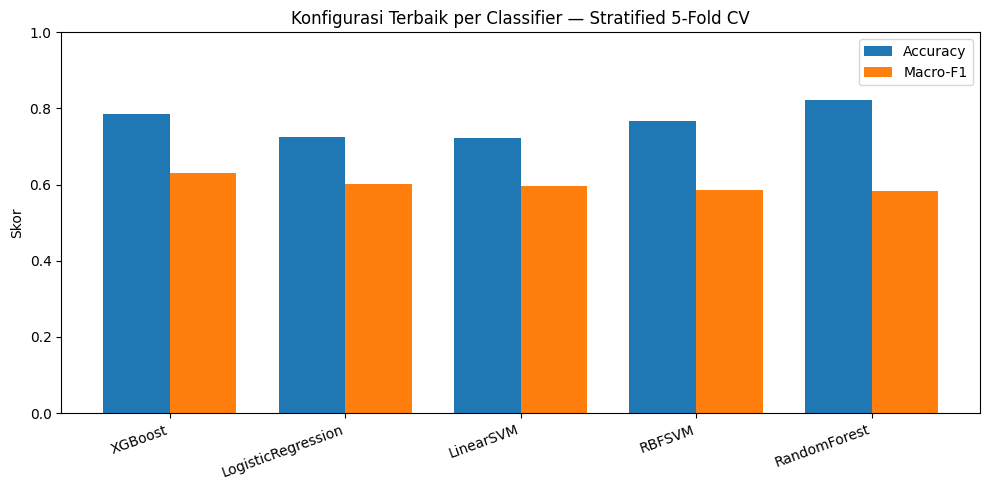

,model,imbalance_strategy,accuracy_mean,macro_f1_mean,balanced_accuracy_mean,f1_negatif_mean,f1_positif_mean
4,XGBoost,smote,0.784267,0.629859,0.623780,0.868739,0.390979
1,LogisticRegression,smote,0.725147,0.601094,0.619350,0.822996,0.379192
0,LinearSVM,smote,0.721319,0.596446,0.612938,0.820372,0.372520
2,RBFSVM,class_weight,0.767033,0.584838,0.577686,0.859486,0.310190
3,RandomForest,smote,0.822454,0.582086,0.571962,0.898986,0.265185


Saved: /content/drive/MyDrive/analisis_sentimen_mbg_effie/artifacts/08_figures/cv_model_comparison_58888f6fe0e0.png


In [ ]:
# Ambil konfigurasi terbaik per keluarga model.
best_per_model = (
    cv_complete
    .sort_values(['macro_f1_mean', 'accuracy_mean'], ascending=False)
    .groupby('model', as_index=False)
    .first()
    .sort_values('macro_f1_mean', ascending=False)
)

fig_path = DIRS['figures'] / f'cv_model_comparison_{SEARCH_HASH[:12]}.png'

plt.figure(figsize=(10, 5))
x = np.arange(len(best_per_model))
width = 0.38

plt.bar(
    x - width/2,
    best_per_model['accuracy_mean'],
    width,
    label='Accuracy'
)
plt.bar(
    x + width/2,
    best_per_model['macro_f1_mean'],
    width,
    label='Macro-F1'
)
plt.xticks(x, best_per_model['model'], rotation=20, ha='right')
plt.ylim(0, 1)
plt.ylabel('Skor')
plt.title('Konfigurasi Terbaik per Classifier — Stratified 5-Fold CV')
plt.legend()
plt.tight_layout()
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()

display(best_per_model[
    [
        'model', 'imbalance_strategy',
        'accuracy_mean', 'macro_f1_mean',
        'balanced_accuracy_mean',
        'f1_negatif_mean', 'f1_positif_mean'
    ]
])
print('Saved:', fig_path)

## 19 — Final evaluation pada unseen test set

Cell ini:
1. load model/config terbaik hasil CV;
2. fit ulang menggunakan seluruh **80% train/dev**;
3. evaluasi sekali pada **20% final test**;
4. simpan classifier, prediction, metrics, confusion matrix, dan error analysis.

Jika artefak final untuk `SEARCH_HASH` yang sama sudah ada, cell **tidak melakukan evaluasi ulang**.

In [ ]:
best = load_json(cv_run_dir / 'best_cv_config.json')

FINAL_RUN_HASH = stable_hash({
    'search_hash': SEARCH_HASH,
    'best_config_id': best['config_id'],
    'final_embedding_hash': EMBED_HASH,
})

final_result_dir = DIRS['results'] / f'final_{FINAL_RUN_HASH[:12]}'
final_model_dir = DIRS['models'] / f'final_{FINAL_RUN_HASH[:12]}'
final_result_dir.mkdir(parents=True, exist_ok=True)
final_model_dir.mkdir(parents=True, exist_ok=True)

final_metrics_path = final_result_dir / 'final_metrics.json'
final_predictions_path = final_result_dir / 'final_predictions.csv'
final_model_path = final_model_dir / 'best_classifier.joblib'
final_manifest_path = final_result_dir / 'final_manifest.json'

if final_metrics_path.exists() and final_predictions_path.exists() and final_model_path.exists():
    print('FINAL TEST SUDAH PERNAH DIJALANKAN untuk konfigurasi ini.')
    print('LOAD artefak final, tidak mengevaluasi ulang.')
    final_metrics = load_json(final_metrics_path)
    final_pred_df = pd.read_csv(final_predictions_path)
else:
    print('MENJALANKAN FINAL TEST SATU KALI...')

    z = np.load(final_embed_path)
    X_train_final = z['X_train']
    y_train_final = z['y_train']
    X_test_final = z['X_test']
    y_test_final = z['y_test']
    final_test_ids = z['test_row_ids'].astype(int)

    best_params = json.loads(best['params_json'])
    estimator = build_estimator(
        best['model'],
        best_params,
        best['imbalance_strategy'],
        y_train_final
    )

    estimator.fit(X_train_final, y_train_final)
    final_pred = estimator.predict(X_test_final).astype(int)

    final_metrics = calc_metrics(y_test_final, final_pred)
    final_metrics.update({
        'model': best['model'],
        'imbalance_strategy': best['imbalance_strategy'],
        'params': best_params,
        'best_cv_config_id': best['config_id'],
        'final_run_hash': FINAL_RUN_HASH,
        'selection_metric': 'macro_f1_mean',
        'created_at': now_iso(),
    })

    test_rows = df_by_id.loc[final_test_ids].copy().reset_index()
    final_pred_df = test_rows[
        [
            'row_id', 'full_text', 'normalized_text',
            'preprocessed_text', 'label', 'y'
        ]
    ].copy()
    final_pred_df['y_pred'] = final_pred
    final_pred_df['label_pred'] = final_pred_df['y_pred'].map(
        {0: 'N', 1: 'P'}
    )
    final_pred_df['benar'] = (
        final_pred_df['y'] == final_pred_df['y_pred']
    )

    save_json(final_metrics, final_metrics_path)
    final_pred_df.to_csv(final_predictions_path, index=False)
    joblib.dump(estimator, final_model_path)

    save_json({
        'final_run_hash': FINAL_RUN_HASH,
        'dataset_sha256': DATASET_SHA,
        'preprocess_hash': PREPROCESS_HASH,
        'split_hash': SPLIT_HASH,
        'vocab_hash': VOCAB_HASH,
        'embedding_hash': EMBED_HASH,
        'search_hash': SEARCH_HASH,
        'best_cv_config': best,
        'environment_file': str(DIRS['manifests'] / 'environment.json'),
        'created_at': now_iso(),
    }, final_manifest_path)

print(json.dumps(final_metrics, indent=2, ensure_ascii=False))
display(final_pred_df.head())

FINAL TEST SUDAH PERNAH DIJALANKAN untuk konfigurasi ini.
LOAD artefak final, tidak mengevaluasi ulang.
{
  "accuracy": 0.7651515151515151,
  "macro_f1": 0.5693991371145954,
  "weighted_f1": 0.7497552606991732,
  "balanced_accuracy": 0.5639252336448598,
  "precision_negatif": 0.8333333333333334,
  "recall_negatif": 0.8878504672897196,
  "f1_negatif": 0.8597285067873304,
  "support_negatif": 107,
  "precision_positif": 0.3333333333333333,
  "recall_positif": 0.24,
  "f1_positif": 0.27906976744186046,
  "support_positif": 25,
  "model": "XGBoost",
  "imbalance_strategy": "smote",
  "params": {
    "learning_rate": 0.03,
    "max_depth": 2,
    "n_estimators": 300
  },
  "best_cv_config_id": "346d908be2a21a0d",
  "final_run_hash": "eef5c7fd1e96b55b03f09cfc85d9e8fe2f6998133e86b6437bd89817396231b5",
  "selection_metric": "macro_f1_mean",
  "created_at": "2026-08-10T04:18:13.927954+00:00"
}


,row_id,full_text,normalized_text,preprocessed_text,label,y,y_pred,label_pred,benar
0,2,@RizkiDimasDwij @masgah_ @Ipaahu La iya dana b...,lah iya dana bos saja dikorup apalagi ada proy...,lah iya dana bos dikorup proyek makan siang gr...,N,0,0,N,True
1,17,Udah guru honorer digaji gak layak trs dipoton...,sudah guru honorer digaji tidak layak terus di...,guru honorer digaji tidak layak terus dipotong...,N,0,0,N,True
2,26,@pakarkampanye Makan siang gratis yang gak gra...,makan siang gratis yang tidak gratis intinya m...,makan siang gratis tidak gratis intinya bikin ...,N,0,0,N,True
3,27,@PaimoMontok 58% rakyat Indonesia kena prank. ...,rakyat indonesia kena prank habis makan bansos...,rakyat indonesia kena prank habis makan bansos...,N,0,0,N,True
4,28,@AnggaPutraF Lebih baik makan siang ama susu g...,lebih baik makan siang sama susu gratis tidak sih,lebih baik makan siang sama susu gratis tidak sih,P,1,0,N,False


## 20 — Classification report + confusion matrix

              precision    recall  f1-score   support

     Negatif     0.8333    0.8879    0.8597       107
     Positif     0.3333    0.2400    0.2791        25

    accuracy                         0.7652       132
   macro avg     0.5833    0.5639    0.5694       132
weighted avg     0.7386    0.7652    0.7498       132



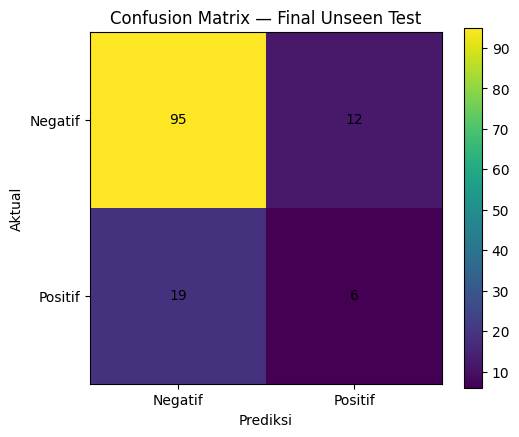

Saved: /content/drive/MyDrive/analisis_sentimen_mbg_effie/artifacts/08_figures/confusion_matrix_eef5c7fd1e96.png


In [ ]:
y_true = final_pred_df['y'].to_numpy(dtype=int)
y_pred = final_pred_df['y_pred'].to_numpy(dtype=int)

report_text = classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=['Negatif', 'Positif'],
    digits=4,
    zero_division=0
)
print(report_text)

with open(final_result_dir / 'classification_report.txt', 'w', encoding='utf-8') as f:
    f.write(report_text)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

cm_path = DIRS['figures'] / f'confusion_matrix_{FINAL_RUN_HASH[:12]}.png'
plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm)
plt.title('Confusion Matrix — Final Unseen Test')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.xticks([0, 1], ['Negatif', 'Positif'])
plt.yticks([0, 1], ['Negatif', 'Positif'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center')

plt.colorbar()
plt.tight_layout()
plt.savefig(cm_path, dpi=200, bbox_inches='tight')
plt.show()

print('Saved:', cm_path)

## 21 — Error analysis

In [ ]:
errors = final_pred_df[~final_pred_df['benar']].copy()

def error_type(row):
    if row['y'] == 0 and row['y_pred'] == 1:
        return 'Negatif diprediksi Positif'
    if row['y'] == 1 and row['y_pred'] == 0:
        return 'Positif diprediksi Negatif'
    return 'Lainnya'

if len(errors):
    errors['jenis_error'] = errors.apply(error_type, axis=1)

error_path = final_result_dir / 'error_analysis.csv'
errors.to_csv(error_path, index=False)

print('Jumlah salah klasifikasi:', len(errors))
if len(errors):
    display(errors[
        [
            'row_id', 'label', 'label_pred', 'jenis_error',
            'full_text', 'preprocessed_text'
        ]
    ])
print('Saved:', error_path)

Jumlah salah klasifikasi: 31


,row_id,label,label_pred,jenis_error,full_text,preprocessed_text
4,28,P,N,Positif diprediksi Negatif,@AnggaPutraF Lebih baik makan siang ama susu g...,lebih baik makan siang sama susu gratis tidak sih
11,71,P,N,Positif diprediksi Negatif,"@TirtoID gakpapa, gak masalah yang penting dap...",enggak apa apa tidak masalah penting makan sia...
12,75,N,P,Negatif diprediksi Positif,"Udah dikasih capres yang mau realisasikan ini,...",dikasih capres mau realisasikan malah pilih ca...
15,78,P,N,Positif diprediksi Negatif,@vanzeiks emang ðŸ’™ aku udah ngga sabar makan...,memang tm aku tidak sabar makan siang gratis m...
17,93,P,N,Positif diprediksi Negatif,@kompascom ALANGKAH LUCU. Sebenarnya makan sia...,alangkah lucu sebenarnya makan siang gratis pr...
18,101,N,P,Negatif diprediksi Positif,@SlamyHwa @BSbukit Kan yang menikmati makan si...,kan menikmati makan siang gratis cuma anak doa...
24,130,P,N,Positif diprediksi Negatif,"Maksi gratis menurut gue bagus bgt, Bagi gue ...",maksi gratis bagus sangat pernah hidup plosok ...
31,179,P,N,Positif diprediksi Negatif,@mediajelata @Ipaahu Makan siang gratis bagi s...,makan siang gratis siswa sekolah dilaksanakan ...
35,222,P,N,Positif diprediksi Negatif,@hansssolo Dek anda yg iQnya rendah gak bisa m...,dek iqnya rendah tidak bisa menangkap arti ses...
41,250,N,P,Negatif diprediksi Positif,@tukang_koya @horcruxesssss @xopch Demi makan ...,makan siang gratis apbn sebagian kementrian ba...


Saved: /content/drive/MyDrive/analisis_sentimen_mbg_effie/artifacts/07_results/final_eef5c7fd1e96/error_analysis.csv


## 22 — Ringkasan seluruh artefak penting

Cell terakhir ini membuat `experiment_summary.json` untuk memudahkan penulisan Bab IV.

In [ ]:
summary = {
    'experiment_version': EXPERIMENT_VERSION,
    'dataset': {
        'path': str(DATASET_PATH),
        'sha256': DATASET_SHA,
        'n_rows': int(len(dfp)),
        'label_distribution': dfp['label'].value_counts().to_dict(),
    },
    'preprocessing': {
        'hash': PREPROCESS_HASH,
        'lexicon_sha256': LEXICON_SHA,
        'dataset_preprocessed': str(preprocessed_path),
        'normalization_report': str(norm_report_path),
        'stemming': False,
        'selective_stopwords': USE_SELECTIVE_STOPWORDS,
    },
    'fasttext': {
        'source': FASTTEXT_VEC_URL,
        'dimension': FASTTEXT_DIM,
        'vocab_hash': VOCAB_HASH,
        'vector_cache': str(ft_cache_path),
        'coverage_report': coverage_meta,
        'oov_report': str(oov_path),
    },
    'split': {
        'hash': SPLIT_HASH,
        'test_size': TEST_SIZE,
        'n_splits_cv': N_SPLITS,
        'random_state': RANDOM_STATE,
        'train_test_artifact': str(split_npz),
        'cv_folds_artifact': str(folds_json),
    },
    'embedding': {
        'name': 'FastText-SIF',
        'hash': EMBED_HASH,
        'sif_a': SIF_A,
        'dimension': FASTTEXT_DIM,
    },
    'model_selection': {
        'search_hash': SEARCH_HASH,
        'primary_metric': 'Macro-F1',
        'best_cv_config': best,
        'cv_summary': str(cv_summary_path),
    },
    'final_test': final_metrics,
    'artifacts': {
        'best_classifier': str(final_model_path),
        'final_predictions': str(final_predictions_path),
        'final_metrics': str(final_metrics_path),
        'error_analysis': str(error_path),
        'confusion_matrix': str(cm_path),
    },
    'created_at': now_iso(),
}

summary_path = final_result_dir / 'experiment_summary.json'
save_json(summary, summary_path)

print('EXPERIMEN SELESAI')
print('=' * 70)
print('Best model   :', final_metrics['model'])
print('Imbalance    :', final_metrics['imbalance_strategy'])
print('Accuracy     :', f"{final_metrics['accuracy']:.4f}")
print('Macro-F1     :', f"{final_metrics['macro_f1']:.4f}")
print('Weighted-F1  :', f"{final_metrics['weighted_f1']:.4f}")
print('Balanced Acc :', f"{final_metrics['balanced_accuracy']:.4f}")
print('=' * 70)
print('Summary:', summary_path)

EXPERIMEN SELESAI
Best model   : XGBoost
Imbalance    : smote
Accuracy     : 0.7652
Macro-F1     : 0.5694
Weighted-F1  : 0.7498
Balanced Acc : 0.5639
Summary: /content/drive/MyDrive/analisis_sentimen_mbg_effie/artifacts/07_results/final_eef5c7fd1e96/experiment_summary.json


# Catatan penggunaan

### Run pertama
Jalankan berurutan dari **00 sampai 22**.

Bagian yang paling lama pada run pertama biasanya:
- download/stream FastText;
- pencarian konfigurasi classifier.

### Run berikutnya
Tetap jalankan cell setup/import dan load sampai tahap yang dibutuhkan. Cell-cell artefak akan mendeteksi file yang sudah ada dan melakukan **LOAD**, bukan menghitung dari awal.

### Jika `lexicon_mbg.csv` diedit
Jalankan ulang mulai **05**. Hash preprocessing berubah sehingga downstream memakai artefak baru tanpa menimpa eksperimen lama.

### Jika dataset berubah
Hash dataset berubah. Split, preprocessing, embedding, dan eksperimen baru akan mendapat hash baru.

### Jangan menghapus
Folder:
- `05_splits`
- `07_results`
- `09_manifests`

karena ketiganya penting untuk reproducibility skripsi.

### Sumber metodologis utama
- fastText pretrained vectors: https://fasttext.cc/docs/en/crawl-vectors.html
- Colloquial Indonesian Lexicon: https://github.com/nasalsabila/kamus-alay
- scikit-learn SVC: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
- imbalanced-learn pipeline/SMOTE: https://imbalanced-learn.org/stable/
- XGBoost parameters: https://xgboost.readthedocs.io/en/stable/parameter.html